# Looping Tornado: 128-frame 3D volume playback

Explore JangaFX's **Looping Tornado** as a shaded smoke volume through **Trame
inside this notebook**. Use Play / Pause, drag the frame slider, adjust smoke
opacity, and rotate or zoom the scene. A **viridis density heat map** and
a fixed density color scale show the smoke structure consistently across frames.

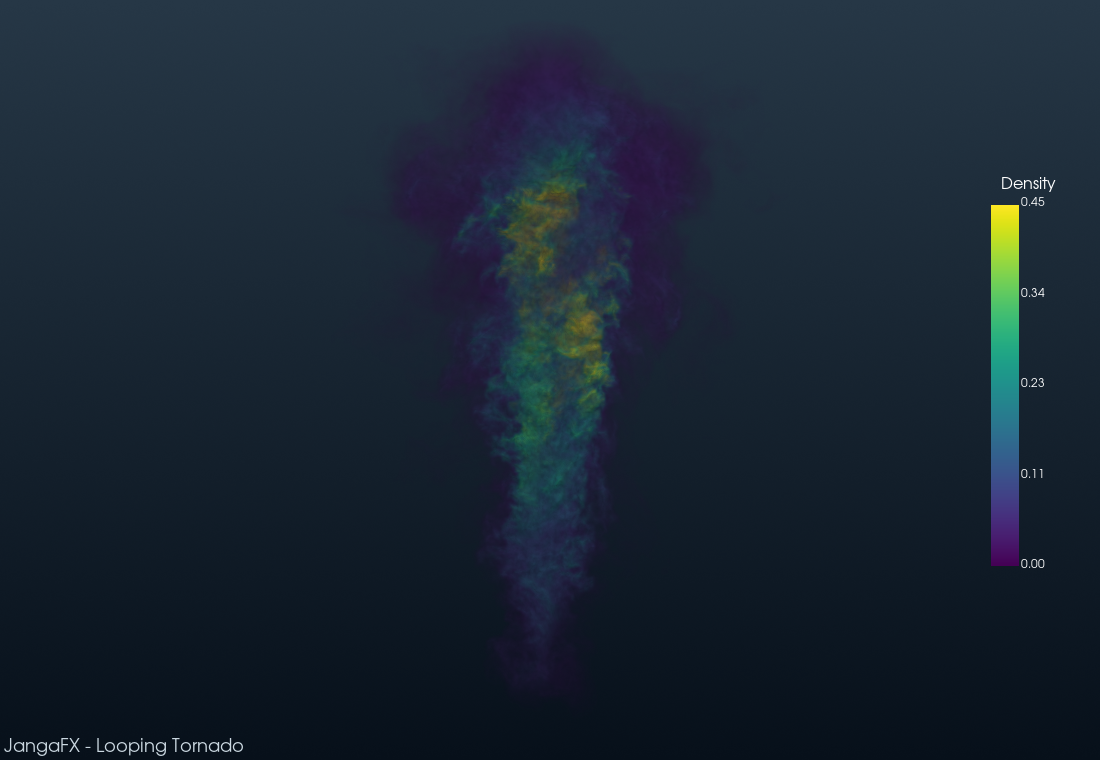

The verified archive contains **128 OpenVDB frames** (`0000...0127`). The catalog
advertises 200 frames, but the actual ZIP contains 128; all are included here.
The verified ZIP is
**1,797,795,595 bytes (1.80 GB / 1.67 GiB)**. Extracted VDBs and the display cache
need additional space. Data and the OpenVDB reader live in the PyVista cache;
they are reused on later runs.

Run All using the same Python environment as the other playback notebooks.
Required packages: PyVista with its `io` extra, NumPy, requests, tqdm, Trame,
trame-vuetify, and trame-pyvista. A working OpenGL context is required.

## Source and first-time setup

The files are from [JangaFX's free VDB catalog](https://www.jangafx.com/software/embergen/download/free-vdb-animations),
released as **CC0 / public domain**. [Official preview](https://www.jangafx.com/media/videos/eg-free-vdbs/tornado-looping.webm).
This is a VFX simulation, with no scientific units asserted.

If the source is not already cached, [download the ZIP in your browser](https://www.mediafire.com/file/fynwmhozanxv821/TornadoLoopingVDB.zip/file)
and leave `TornadoLoopingVDB.zip` in Downloads. The setup cell verifies its
SHA-256 and moves it into the cache. It extracts the VDB files and
the accompanying license/readme, without running the included EmberGen preset.

An isolated OpenVDB reader is installed automatically from conda-forge through
the official micromamba distribution on macOS/Linux. It does not alter this
notebook's Python environment or your shell configuration.

The color scale stays fixed across frames. Its upper limit uses the maximum
per-frame 99.5th-percentile positive density; higher values use the top color.


In [ ]:
from __future__ import annotations

import asyncio
import hashlib
import io
import json
from pathlib import Path
import platform
import re
import shutil
import subprocess
import tarfile
import uuid
import zipfile

import numpy as np
import requests
from tqdm.auto import tqdm
from trame.ui.vuetify3 import SinglePageLayout
from trame.widgets import vuetify3 as v3
from trame_pyvista.ui.vuetify3 import Viewer
from trame_server import Server

import pyvista as pv
from pyvista import examples

previous_close = globals().get('close_tornado_trame')
if previous_close is not None:
    await previous_close()
del previous_close

cache_root = Path(examples.USER_DATA_PATH) / 'tornado_looping'
cache_root.mkdir(parents=True, exist_ok=True)
archive_path = cache_root / 'TornadoLoopingVDB.zip'
archive_bytes = 1_797_795_595
archive_sha256 = '492c99321ae911d0ad6c6ff3df6eb53c83e443ba91b6aab7b97ba86e536ac57c'
max_display_dimension = 256
display_cycle_seconds = 12.0

## Local Trame configuration

Run this cell before creating the view when Jupyter or Antigravity is running
on this Mac. It uses a local loopback server and disables JupyterHub proxy and
extension routing. The volume is rendered locally and streamed into the notebook.


In [ ]:
pv.global_theme.trame.server_proxy_enabled = False
pv.global_theme.trame.jupyter_extension_enabled = False
pv.set_jupyter_backend('trame')
trame_host = '127.0.0.1'

In [ ]:
def file_sha256(path: Path) -> str:
    """Hash a file without loading it into memory."""
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 2**20), b''):
            digest.update(block)
    return digest.hexdigest()


def prepare_source() -> list[Path]:
    """Verify the archive and extract the exact 128 VDB frames safely."""
    candidate = (
        archive_path if archive_path.exists() else Path.home() / 'Downloads' / archive_path.name
    )
    if not candidate.is_file():
        msg = 'Download TornadoLoopingVDB.zip using the link above, then rerun this cell.'
        raise FileNotFoundError(msg)
    if candidate.stat().st_size != archive_bytes or file_sha256(candidate) != archive_sha256:
        msg = 'The tornado archive size or SHA-256 does not match the original source.'
        raise ValueError(msg)
    if candidate != archive_path:
        shutil.move(str(candidate), str(archive_path))
    folder = cache_root / 'vdb'
    folder.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        members = sorted(
            (
                item
                for item in archive.infolist()
                if re.fullmatch(r'tornado_\d{4}\.vdb', Path(item.filename).name)
            ),
            key=lambda item: Path(item.filename).name,
        )
        if [Path(item.filename).name for item in members] != [
            f'tornado_{i:04d}.vdb' for i in range(128)
        ]:
            msg = 'Expected the complete tornado_0000 through tornado_0127 sequence.'
            raise ValueError(msg)
        for item in tqdm(members, desc='Original VDB frames', unit='frame'):
            target = folder / Path(item.filename).name
            if target.exists() and target.stat().st_size == item.file_size:
                continue
            temporary = target.with_suffix('.partial')
            with archive.open(item) as source, temporary.open('wb') as output:
                shutil.copyfileobj(source, output)
            temporary.replace(target)
        for name in ('LICENSE.txt', 'README.txt'):
            if name in archive.namelist():
                (cache_root / name).write_bytes(archive.read(name))
    return [folder / Path(item.filename).name for item in members]


vdb_paths = prepare_source()
{
    'frames': len(vdb_paths),
    'archive_bytes': archive_path.stat().st_size,
    'extracted_vdb_bytes': sum(path.stat().st_size for path in vdb_paths),
    'cache': str(cache_root),
}

## Prepare the smoke display

All 128 timestamps are retained. For responsive volume rendering, each density
grid is sampled to roughly **256 voxels along its longest active dimension**.
The original full-resolution VDBs remain available. Change
`max_display_dimension` above to create a different display cache.

Only one dense source frame is converted at a time. Converted frames use
PyVista's compressed `.pv` format; temporary NumPy bridge files are removed.
The OpenVDB world transform and voxel spacing are preserved. First preparation
takes longer; subsequent runs reuse completed display frames.


In [ ]:
def prepare_openvdb_reader() -> Path:
    """Install an isolated reader without modifying the notebook environment."""
    tools = cache_root / 'tools'
    reader = tools / 'openvdb' / 'bin' / 'python'
    if reader.is_file():
        subprocess.run([str(reader), '-c', 'import openvdb, numpy'], check=True)
        return reader
    systems = {
        ('Darwin', 'arm64'): 'osx-arm64',
        ('Darwin', 'x86_64'): 'osx-64',
        ('Linux', 'x86_64'): 'linux-64',
        ('Linux', 'aarch64'): 'linux-aarch64',
    }
    subdir = systems.get((platform.system(), platform.machine()))
    if subdir is None:
        msg = 'This automatic reader setup supports macOS and Linux.'
        raise RuntimeError(msg)
    executable = tools / 'bin' / 'micromamba'
    if not executable.is_file():
        response = requests.get(
            f'https://micro.mamba.pm/api/micromamba/{subdir}/latest', timeout=180
        )
        response.raise_for_status()
        executable.parent.mkdir(parents=True, exist_ok=True)
        with tarfile.open(fileobj=io.BytesIO(response.content), mode='r:bz2') as package:
            member = package.getmember('bin/micromamba')
            if not member.isfile():
                msg = 'The micromamba executable is not a regular file.'
                raise ValueError(msg)
            with package.extractfile(member) as source, executable.open('wb') as output:
                shutil.copyfileobj(source, output)
        executable.chmod(0o755)
    subprocess.run(
        [
            str(executable),
            'create',
            '--no-rc',
            '-y',
            '--root-prefix',
            str(tools / 'mamba'),
            '--prefix',
            str(tools / 'openvdb'),
            '-c',
            'conda-forge',
            '--strict-channel-priority',
            'python=3.13',
            'openvdb=13.1',
            'numpy',
        ],
        check=True,
    )
    return reader


reader_python = prepare_openvdb_reader()

In [ ]:
converter_source = r'''
"""Convert OpenVDB density grids to NumPy bridge files for PyVista."""

import argparse
import json
import math
from pathlib import Path

import numpy as np
import openvdb as vdb


def convert(path: Path, output: Path, max_dimension: int) -> dict:
    """Preserve world coordinates while sampling one padded density grid."""
    grid = vdb.read(str(path), 'density')
    lower, upper = (np.asarray(value, dtype=int) for value in grid.evalActiveVoxelBoundingBox())
    if np.any(upper < lower):
        raise ValueError('The density grid is empty.')
    original_shape = upper - lower + 1
    stride = max(1, math.ceil((int(original_shape.max()) + 2) / max_dimension))
    lower -= stride
    upper += stride
    dense = np.empty(tuple(int(value) for value in upper - lower + 1), dtype=np.float32)
    grid.copyToArray(dense, ijk=tuple(int(value) for value in lower))
    density = np.ascontiguousarray(dense[::stride, ::stride, ::stride])
    del dense
    origin = np.asarray(grid.transform.indexToWorld(tuple(int(value) for value in lower)))
    basis = np.column_stack([
        np.asarray(grid.transform.indexToWorld(tuple(int(value) for value in lower + axis)))
        - origin
        for axis in np.eye(3, dtype=int)
    ])
    spacing = np.linalg.norm(basis, axis=0)
    direction = basis / spacing
    np.testing.assert_allclose(direction.T @ direction, np.eye(3), atol=1e-8)
    if not np.isfinite(density).all() or float(density.min()) < 0:
        raise ValueError('Expected finite nonnegative fog density.')
    positive = density[density > 0]
    summary = {
        'source': path.name,
        'source_shape': original_shape.tolist(),
        'display_shape': list(density.shape),
        'stride': stride,
        'density_max': float(density.max()),
        'density_p995': float(np.quantile(positive, 0.995)) if positive.size else 0.0,
        'simulation_time': float(grid.metadata.get('simulation_time', 0)),
    }
    temporary = output.with_suffix('.tmp.npz')
    np.savez(
        temporary, density=density, origin=origin, spacing=spacing * stride, direction=direction
    )
    temporary.replace(output)
    return summary


def main() -> None:
    """Convert requested frames and emit one metadata line per completed frame."""
    parser = argparse.ArgumentParser()
    parser.add_argument('--inputs', nargs='+', required=True, type=Path)
    parser.add_argument('--output-dir', required=True, type=Path)
    parser.add_argument('--max-dimension', type=int, default=256)
    args = parser.parse_args()
    args.output_dir.mkdir(parents=True, exist_ok=True)
    for path in args.inputs:
        output = args.output_dir / f'{path.stem}.npz'
        result = convert(path, output, args.max_dimension)
        result['bridge_file'] = str(output)
        print(json.dumps(result), flush=True)


if __name__ == '__main__':
    main()
'''
converter_path = cache_root / 'tools' / 'convert_density.py'
converter_path.write_text(converter_source)

In [ ]:
def prepare_display_cache() -> tuple[list[Path], list[dict]]:
    """Resume conversion into compressed, independently readable PyVista frames."""
    folder = cache_root / f'display-{max_display_dimension}'
    folder.mkdir(exist_ok=True)
    manifest_path = folder / 'frames.json'
    config = {
        'source_sha256': archive_sha256,
        'max_dimension': max_display_dimension,
        'version': 1,
    }
    manifest = (
        json.loads(manifest_path.read_text())
        if manifest_path.exists()
        else {'config': config, 'frames': {}}
    )
    if manifest['config'] != config:
        msg = 'The display cache configuration does not match this conversion.'
        raise ValueError(msg)
    pending = [
        path
        for path in vdb_paths
        if path.name not in manifest['frames'] or not (folder / f'{path.stem}.pv').exists()
    ]
    if pending:
        bridge_folder = folder / 'bridge'
        bridge_folder.mkdir(exist_ok=True)
        command = [
            str(reader_python),
            str(converter_path),
            '--inputs',
            *map(str, pending),
            '--output-dir',
            str(bridge_folder),
            '--max-dimension',
            str(max_display_dimension),
        ]
        diagnostics = []
        with subprocess.Popen(
            command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
        ) as process:
            try:
                if process.stdout is None:
                    msg = 'The density converter did not provide an output stream.'
                    raise RuntimeError(msg)
                with tqdm(total=len(pending), desc='Display volumes', unit='frame') as progress:
                    for line in process.stdout:
                        try:
                            record = json.loads(line)
                        except json.JSONDecodeError:
                            diagnostics.append(line)
                            continue
                        bridge_path = Path(record.pop('bridge_file'))
                        with np.load(bridge_path) as data:
                            mesh = pv.ImageData(
                                dimensions=data['density'].shape,
                                spacing=data['spacing'],
                                origin=data['origin'],
                                direction_matrix=data['direction'],
                            )
                            mesh['density'] = data['density'].ravel(order='F')
                        mesh.set_active_scalars('density')
                        mesh.field_data['source_time'] = np.array([record['simulation_time']])
                        destination = folder / f'{Path(record["source"]).stem}.pv'
                        temporary = destination.with_suffix('.tmp.pv')
                        mesh.save(temporary)
                        temporary.replace(destination)
                        record['bounds'] = list(mesh.bounds)
                        record['display_file'] = destination.name
                        manifest['frames'][record['source']] = record
                        temporary_manifest = manifest_path.with_suffix('.tmp')
                        temporary_manifest.write_text(json.dumps(manifest))
                        temporary_manifest.replace(manifest_path)
                        bridge_path.unlink()
                        progress.update()
                if process.wait() != 0:
                    msg = 'The OpenVDB converter failed: ' + ''.join(diagnostics)[-4000:]
                    raise RuntimeError(msg)
            except BaseException:
                process.terminate()
                process.wait()
                raise
        if not any(bridge_folder.iterdir()):
            bridge_folder.rmdir()
    records = [manifest['frames'][path.name] for path in vdb_paths]
    return [folder / record['display_file'] for record in records], records


display_files, frame_records = prepare_display_cache()
frame_count = len(display_files)
all_bounds = np.array([record['bounds'] for record in frame_records]).reshape(-1, 3, 2)
display_bounds = np.column_stack(
    (all_bounds[:, :, 0].min(axis=0), all_bounds[:, :, 1].max(axis=0))
).ravel()
display_up = np.eye(3)[
    np.argmax(display_bounds.reshape(3, 2)[:, 1] - display_bounds.reshape(3, 2)[:, 0])
]
density_clim = (0.0, max(record['density_p995'] for record in frame_records))


def load_frame(index: int) -> pv.ImageData:
    """Read one saved density volume on demand."""
    return pv.read(display_files[index])


{
    'ready_frames': frame_count,
    'display_cache_bytes': sum(path.stat().st_size for path in display_files),
    'density_range': density_clim,
    'display_resolution_example': frame_records[0]['display_shape'],
}

In [ ]:
async def make_tornado_trame() -> tuple[SinglePageLayout, object]:
    """Create a volume-rendered Trame player and its cleanup callback."""
    server = Server(f'tornado-{uuid.uuid4().hex}', client_type='vue3')
    state = server.state
    state.frame = 0
    state.frame_count = frame_count
    state.playing = False
    state.smoke_opacity = 1.0
    playback_task: asyncio.Task[None] | None = None
    closed = False

    initial = load_frame(0)
    initial.set_active_scalars('density', preference='point')
    pl = pv.Plotter(notebook=True, off_screen=True, window_size=(1100, 760))
    pl.set_background('#07101a', top='#263746')
    opacity_curve = np.linspace(0.0, 1.0, 256) ** 1.0 * 0.35
    smoke_lut = pv.LookupTable(cmap='viridis', n_values=256, scalar_range=density_clim)
    colors = smoke_lut.values.copy()
    colors[:, 3] = (opacity_curve * 255).astype(np.uint8)
    smoke_lut.values = colors
    actor = pl.add_volume(
        initial,
        scalars='density',
        clim=density_clim,
        cmap=smoke_lut,
        opacity=(opacity_curve * 255).astype(np.uint8),
        n_colors=256,
        mapper='smart',
        blending='composite',
        shade=True,
        ambient=0.35,
        diffuse=0.7,
        specular=0.05,
        specular_power=15,
        opacity_unit_distance=max(initial.spacing),
        show_scalar_bar=True,
        scalar_bar_args={
            'title': 'Density',
            'use_opacity': False,
            'vertical': True,
            'height': 0.5,
            'width': 0.07,
            'position_x': 0.9,
            'position_y': 0.25,
            'color': 'white',
            'title_font_size': 16,
            'label_font_size': 12,
            'fmt': '%.2f',
        },
    )
    actor.prop.interpolation_type = 'linear'
    player = pv.TimeSeriesPlayer(
        pl,
        range(frame_count),
        load_frame,
        cycle_end=frame_count,
        scalars='density',
        clim=density_clim,
        actor=actor,
        render=False,
    )
    bounds = np.asarray(display_bounds, dtype=float).reshape(3, 2)
    center = bounds.mean(axis=1)
    radius = float(np.linalg.norm(bounds[:, 1] - bounds[:, 0])) / 2
    up = np.asarray(display_up, dtype=float)
    horizontal = np.array([1.0, 0.0, 0.0]) if abs(up[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    side = np.cross(up, horizontal)
    camera_position = center + radius * (2.1 * horizontal - 3.2 * side + 1.0 * up)
    pl.camera_position = (camera_position, center, up)
    pl.enable_parallel_projection()
    pl.camera.parallel_scale = radius * 0.7
    pl.add_text('JangaFX - Looping Tornado', position='lower_left', font_size=9, color='#cad7e0')
    viewer = Viewer(pl, server=server)

    def update_display() -> None:
        """Publish the API's current sample through the existing view."""
        with state:
            state.frame = player.index
        pl.reset_camera_clipping_range()
        pl.render()
        viewer.update()

    @state.change('frame')
    def seek_frame(*, frame: int, **_kwargs) -> None:
        """Seek through the time series API without changing the camera."""
        if not closed and int(frame) != player.index:
            player.seek_index(int(frame))
            update_display()

    async def animate() -> None:
        """Drive the API from the application's existing timer task."""
        while not closed and player.playing:
            await asyncio.sleep(1 / 30)
            if not closed:
                previous = player.index
                player.tick()
                if player.index != previous:
                    update_display()

    @state.change('playing')
    def set_playing(*, playing: bool, **_kwargs) -> None:
        """Start or pause API playback using the existing controls."""
        nonlocal playback_task
        if closed:
            return
        if playing:
            player.play(display_cycle_seconds)
            if playback_task is None or playback_task.done():
                playback_task = asyncio.create_task(animate())
        else:
            previous = player.index
            player.pause()
            if player.index != previous:
                update_display()
            if playback_task is not None:
                playback_task.cancel()
                playback_task = None

    @state.change('smoke_opacity')
    def set_smoke_opacity(*, smoke_opacity: float, **_kwargs) -> None:
        """Change smoke opacity without replacing the current volume."""
        if not closed:
            alpha = (np.clip(opacity_curve * smoke_opacity, 0, 1) * 255).astype(np.uint8)
            actor.mapper.lookup_table.apply_opacity(alpha)
            pl.render()
            viewer.update()

    with SinglePageLayout(server) as layout:
        layout.title.set_text('Looping Tornado')
        with layout.toolbar:
            v3.VBtn(
                "{{ playing ? 'Pause' : 'Play' }}",
                prepend_icon=("playing ? 'mdi-pause' : 'mdi-play'",),
                click='playing = !playing',
                variant='tonal',
                classes='mr-4',
            )
            v3.VSlider(
                v_model=('frame', 0),
                min=0,
                max=frame_count - 1,
                step=1,
                label='Frame',
                thumb_label=True,
                hide_details=True,
                style='max-width: 280px',
            )
            v3.VChip('{{ frame + 1 }} / {{ frame_count }}', classes='mx-4')
            v3.VSlider(
                v_model=('smoke_opacity', 1.0),
                min=0.1,
                max=3.0,
                step=0.1,
                label='Smoke opacity',
                thumb_label=True,
                hide_details=True,
                style='max-width: 200px',
            )
        with layout.content:
            viewer.ui(mode='server', interactive_ratio=1, interactive_quality=80, still_quality=95)
        layout.footer.hide()

    async def close() -> None:
        """Stop playback and release the server and volume renderer."""
        nonlocal closed, playback_task
        if closed:
            return
        closed = True
        task = playback_task
        with state:
            state.playing = False
        if task is not None:
            task.cancel()
            await asyncio.gather(task, return_exceptions=True)
            playback_task = None
        player.close()
        pl.close()
        await server.stop()

    try:
        server.start(
            exec_mode='task',
            host=trame_host,
            port=0,
            open_browser=False,
            show_connection_info=False,
            timeout=0,
        )
        await layout.ready
    except BaseException:
        await close()
        raise
    return layout, close

In [ ]:
previous_close = globals().get('close_tornado_trame')
if previous_close is not None:
    await previous_close()
del previous_close

tornado_ui, close_tornado_trame = await make_tornado_trame()
tornado_ui

The player retains one displayed volume and loads saved frames as needed.
The application timer chooses the frame due now; slow ticks may skip frames.
The 12-second display cycle is a presentation setting. Rerunning the display
cell closes the previous view first.

To release the view without restarting the kernel, run:

```python
await close_tornado_trame()
```
